In [ ]:
!pip install langchain==0.3.25 \
                langchain-core==0.3.65 \
                langchain-openai==0.3.24 \
                chromadb==1.3.4 \
                langchain-community==0.3.20 \
                pypdf==5.4.0

In [159]:
import yfinance as yf              # Used for gathering stock prices
import matplotlib.pyplot as plt    # Used for Data Visualization / Plots / Graphs
import pandas as pd                # Helpful for working with tabular data like DataFrames
import os                          # Interacting with the operating system

from langchain.text_splitter import RecursiveCharacterTextSplitter      #  Helpful in splitting the PDF into smaller chunks

from langchain_community.document_loaders import PyPDFDirectoryLoader, PyPDFLoader     # Loading a PDF
from langchain_community.vectorstores import Chroma    # Vector DataBase


In [160]:
companies = ["GOOGL", "MSFT", "IBM", "NVDA", "AMZN"]

In [161]:
#Loading the `config.json` file
import json
import os

# Load the JSON file and extract values
file_name = "/content/config.json"
with open(file_name, 'r') as file:
    config = json.load(file)
    os.environ['OPENAI_API_KEY'] = config['API_KEY'] # Loading the API Key
    os.environ["OPENAI_BASE_URL"] = config['OPENAI_API_BASE'] # Loading the API Base Url

In [162]:
from langchain_openai import ChatOpenAI
llm = ChatOpenAI(
    model="gpt-4o-mini",                      # "gpt-4o-mini" to be used as an LLM
    temperature="0",                # Set the temprature to 0
    max_tokens="5000",                 # Set the max_tokens = 5000, so that the long response will not be clipped off
    top_p=0.95,
    frequency_penalty=1.2,
    stop_sequences=['INST']
)

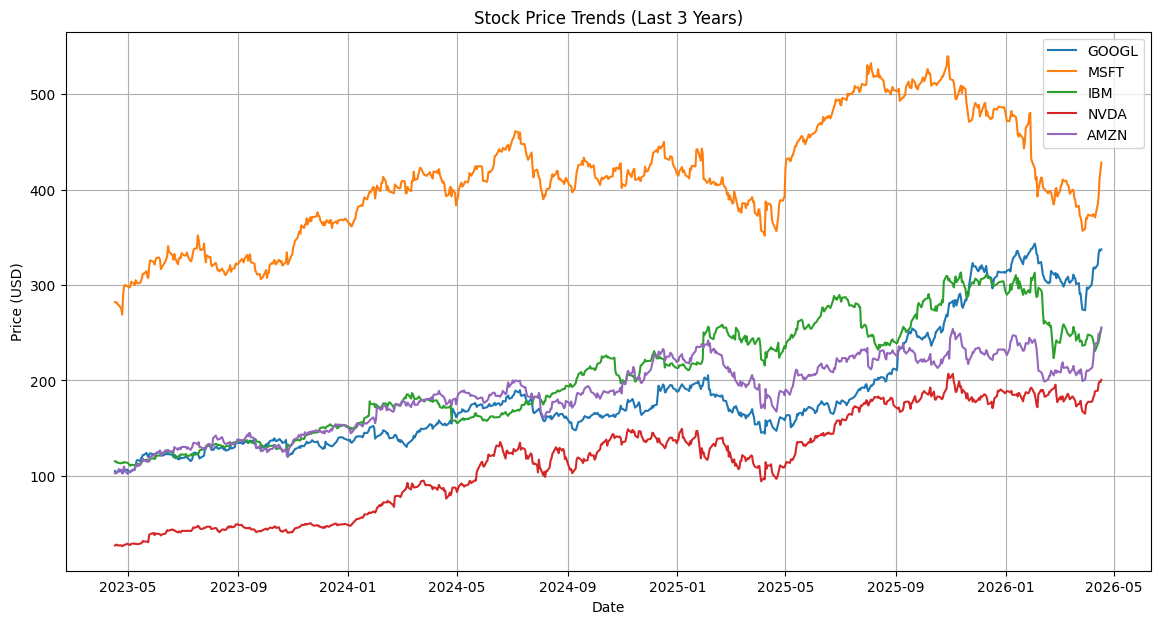

In [163]:
plt.figure(figsize=(14,7))

# Loop through each company and plot closing prices
for symbol in companies:
    ticker = yf.Ticker(symbol)
    data = ticker.history(period="3y")

    # Plot closing price
    plt.plot(data.index, data['Close'], label=symbol)

plt.title("Stock Price Trends (Last 3 Years)")
plt.xlabel("Date")
plt.ylabel("Price (USD)")
plt.legend()
plt.grid(True)
plt.savefig("Stock_Price_Trends_3Y.png")
plt.show()

In [164]:
import pandas as pd
import matplotlib.pyplot as plt

companies = ["GOOGL", "MSFT", "IBM", "NVDA", "AMZN"]
metrics_list = {}

# Fetching the financial metrics
for symbol in companies:                          # Loop through all the companies
    ticker = yf.Ticker(symbol)
    info = ticker.info
    metrics_list[symbol] = {                              # Define the dictionary of all the Finanical Metrics
        "Market Cap": info.get("marketCap", 0),
        "P/E Ratio": info.get("trailingPE", 0),
        "Dividend Yield": info.get("dividendYield", 0),
        "Beta": info.get("beta", 0),
        "Total Revenue": info.get("totalRevenue", 0)
    }
    print(metrics_list)

{'GOOGL': {'Market Cap': 4081286119424, 'P/E Ratio': 31.181147, 'Dividend Yield': 0.25, 'Beta': 1.128, 'Total Revenue': 402835996672}}
{'GOOGL': {'Market Cap': 4081286119424, 'P/E Ratio': 31.181147, 'Dividend Yield': 0.25, 'Beta': 1.128, 'Total Revenue': 402835996672}, 'MSFT': {'Market Cap': 3183361654784, 'P/E Ratio': 26.819662, 'Dividend Yield': 0.87, 'Beta': 1.107, 'Total Revenue': 305453006848}}
{'GOOGL': {'Market Cap': 4081286119424, 'P/E Ratio': 31.181147, 'Dividend Yield': 0.25, 'Beta': 1.128, 'Total Revenue': 402835996672}, 'MSFT': {'Market Cap': 3183361654784, 'P/E Ratio': 26.819662, 'Dividend Yield': 0.87, 'Beta': 1.107, 'Total Revenue': 305453006848}, 'IBM': {'Market Cap': 238703116288, 'P/E Ratio': 22.833931, 'Dividend Yield': 2.68, 'Beta': 0.685, 'Total Revenue': 67534999552}}
{'GOOGL': {'Market Cap': 4081286119424, 'P/E Ratio': 31.181147, 'Dividend Yield': 0.25, 'Beta': 1.128, 'Total Revenue': 402835996672}, 'MSFT': {'Market Cap': 3183361654784, 'P/E Ratio': 26.819662, 'D

In [165]:
# Convert to DataFrame
df = pd.DataFrame(metrics_list).T

# Converting large numbers to billions for readability by divinding the whole column by 1e9
df["Market Cap"] = df["Market Cap"]/ 1e9
df["Total Revenue"] = df["Total Revenue"] / 1e9
df["Dividend Yield"] = df["Dividend Yield"] * 100  # Convert to percentage

df   # Printing the df

,Market Cap,P/E Ratio,Dividend Yield,Beta,Total Revenue
GOOGL,4081.286119,31.181147,25.0,1.128,402.835997
MSFT,3183.361655,26.819662,87.0,1.107,305.453007
IBM,238.703116,22.833931,268.0,0.685,67.535000
NVDA,4874.975576,40.933674,2.0,2.335,215.938007
AMZN,2747.550138,35.632496,0.0,1.383,716.923994


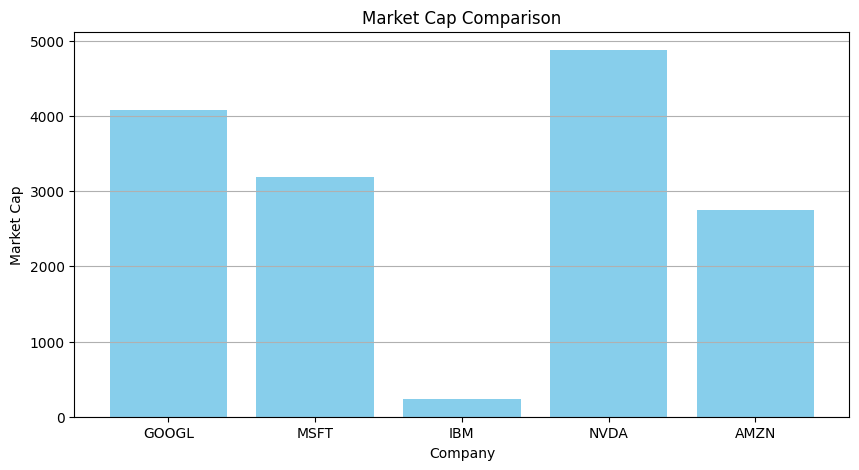

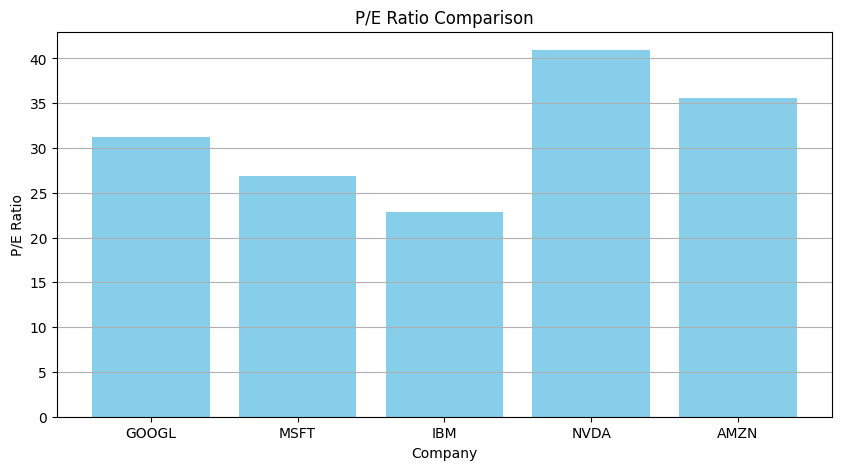

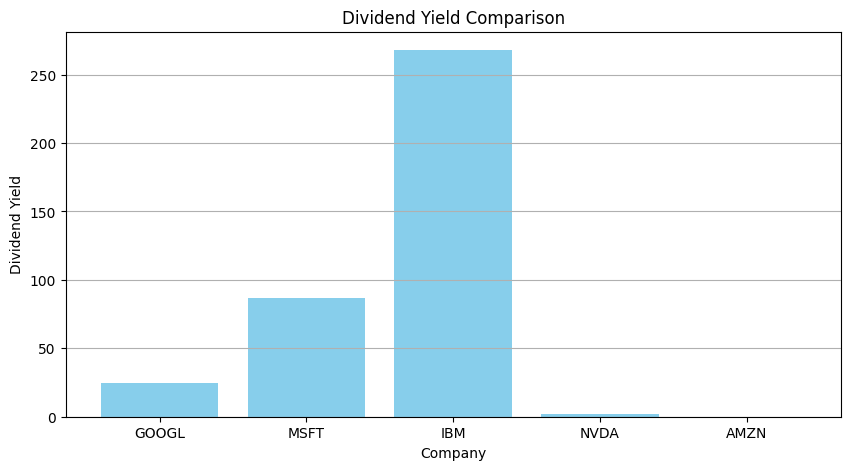

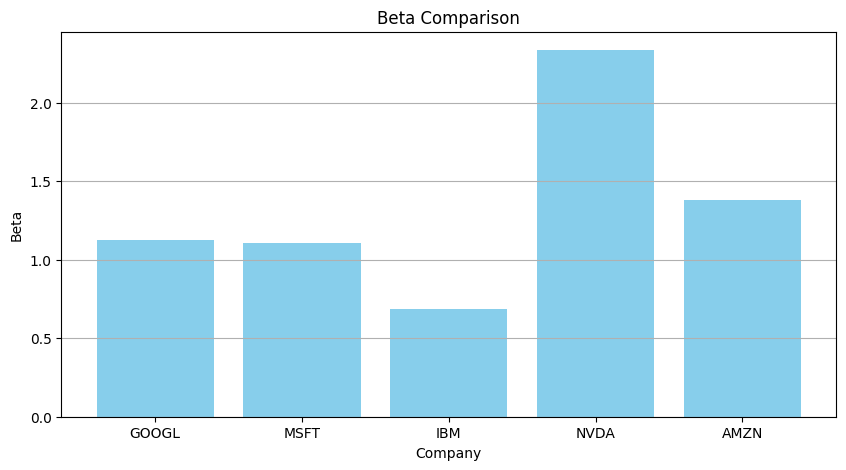

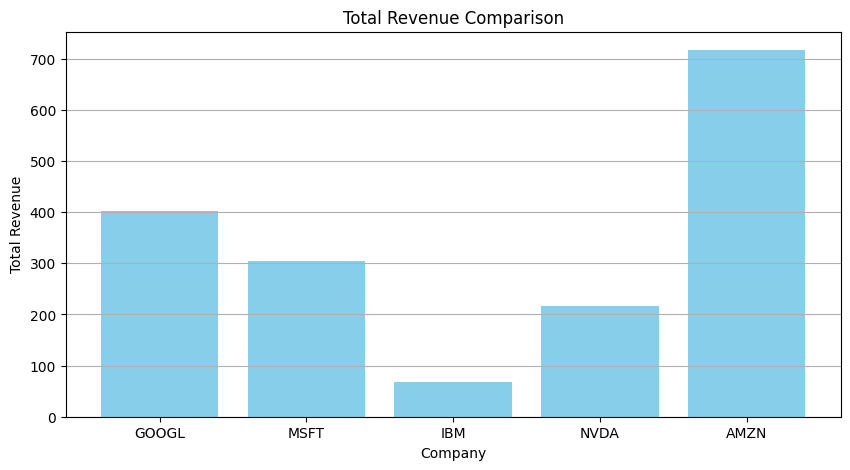

In [166]:
# Plot each metric as a separate bar graph
metrics_to_plot = ["Market Cap", "P/E Ratio", "Dividend Yield", "Beta", "Total Revenue"]

for metric in metrics_to_plot:
    plt.figure(figsize=(10,5))
    plt.bar(df.index, df[metric], color='skyblue')
    plt.title(f"{metric} Comparison")
    plt.ylabel(metric)
    plt.xlabel("Company")
    plt.grid(axis='y')
    plt.show()

In [167]:
# Unzipping the AI Initiatives Documents
import zipfile
with zipfile.ZipFile("/content/Companies-AI-Initiatives.zip", 'r') as zip_ref:
  zip_ref.extractall("/content/")         # Storing all the unzipped contents in this location


In [168]:

# Path of all AI Initiative Documents
ai_initiative_pdf_paths = [f"/content/Companies-AI-Initiatives/{file}" for file in os.listdir("/content/Companies-AI-Initiatives")]
ai_initiative_pdf_paths

['/content/Companies-AI-Initiatives/MSFT.pdf',
 '/content/Companies-AI-Initiatives/GOOGL.pdf',
 '/content/Companies-AI-Initiatives/AMZN.pdf',
 '/content/Companies-AI-Initiatives/NVDA.pdf',
 '/content/Companies-AI-Initiatives/IBM.pdf']

In [169]:
from langchain_community.document_loaders import PyPDFDirectoryLoader
loader = PyPDFDirectoryLoader(path = "/content/Companies-AI-Initiatives/")          # Creating an PDF loader object

In [170]:
# Defining the text splitter
text_splitter = RecursiveCharacterTextSplitter.from_tiktoken_encoder(
    encoding_name='cl100k_base',
    chunk_size=512,
    chunk_overlap=20
)

In [171]:
ai_initiative_chunks = loader.load_and_split(text_splitter)

In [172]:

# Total length of all the chunks
len(ai_initiative_chunks)

102

In [173]:
# Defining the 'text-embedding-ada-002' as the embedding model
from langchain_openai import OpenAIEmbeddings
embedding_model = OpenAIEmbeddings(model="text-embedding-ada-002")

In [174]:
#  Creating a Vectorstore, storing all the above created chunks using an embedding model
vectorstore = Chroma.from_documents(
    ai_initiative_chunks,
    embedding_model,
    collection_name="AI_Initiatives"
)

# Ignore if it gives an error or warning

In [175]:
# Creating an retriever object which can fetch ten similar results from the vectorstore
retriever = vectorstore.as_retriever(
    search_type='similarity',
    search_kwargs={'k':10}
)

In [176]:
user_message = "Give me the best project that `IBM` company is working upon"


In [177]:
# Building the context for the query using the retrieved chunks
relevant_document_chunks = retriever.get_relevant_documents(user_message)
context_list = [d.page_content for d in relevant_document_chunks]
context_for_query = ". ".join(context_list)

In [178]:
# Format the prompt
formatted_prompt = f"""[INST]{qna_system_message}\n
                {'user'}: {qna_user_message_template.format(context=context_for_query, question=user_message)}
                [/INST]"""

In [179]:
# Make the LLM call
resp = llm.invoke(formatted_prompt)
print(resp.content)

The provided context does not specify a single "best" project that IBM is working on. However, it highlights several significant initiatives, including the development of the Granite AI models and the Watsonx platform. Both projects focus on providing scalable, customizable, and secure AI solutions to enhance enterprise operations across various industries. If you need more specific information about a particular project or its impact, please clarify your question.


In [180]:
# Building the context for the query using the retrieved chunks
relevant_document_chunks = retriever.get_relevant_documents(user_message)
context_list = [d.page_content for d in relevant_document_chunks]
context_for_query = ". ".join(context_list)

In [181]:
len(relevant_document_chunks)

10

In [182]:
# Write a system message for an LLM to help craft a response from the provided context
qna_system_message = """You are an AI assistant that answers questions based on the provided context.

Rules:
- Use the information from the retrieved context to answer the question.
- If the information is not explicitly available in the context, state that the answer cannot be found in the provided documents.
- Do not make up information.
- Be concise and clear.
- If relevant, summarize the information.

Answer the user's question based on the context."""

In [183]:
# Write an user message template which can be used to attach the context and the questions
qna_user_message_template = """
###Context
Here are some documents that are relevant to the question mentioned below.
{context}

###Question
{question}
"""

print(qna_user_message_template)


###Context
Here are some documents that are relevant to the question mentioned below.
{context}

###Question
{question}



In [184]:
# Format the prompt
formatted_prompt = f"""[INST]{qna_system_message}\n
                {'user'}: {qna_user_message_template.format(context=context_for_query, question=user_message)}
                [/INST]"""

In [185]:
# Make the LLM call
resp = llm.invoke(formatted_prompt)
resp.content

'The provided context does not specify a single "best" project that IBM is working on. However, it highlights several significant initiatives, including the development of the Granite AI models and the Watsonx platform. These projects focus on providing scalable, customizable, and secure AI solutions to enhance enterprise operations across various industries. If you need more specific information about a particular project or initiative, please clarify your question.'

In [186]:
# Define RAG function
def RAG(user_message):
    """
    Args:
    user_message: Takes a user input for which the response should be retrieved from the vectorDB.
    Returns:
    relevant context as per user query.
    """
    relevant_document_chunks = retriever.get_relevant_documents(user_message)
    context_list = [d.page_content for d in relevant_document_chunks]
    context_for_query = ". ".join(context_list)



    # Combine qna_system_message and qna_user_message_template to create the prompt
    prompt = f"""[INST]{qna_system_message}\n
                {'user'}: {qna_user_message_template.format(context=context_for_query, question=user_message)}
                [/INST]"""

    # Quering the LLM
    try:
        response = llm.invoke(prompt)

    except Exception as e:
        response = f'Sorry, I encountered the following error: \n {e}'

    return response.content

In [187]:
# Test Cases
print(RAG("How is the area in which GOOGL is working different from the area in which MSFT is working?"))

Google (GOOGL) focuses on a broad range of AI applications, including natural language processing, computer vision, speech recognition, and generative AI. Its initiatives like Google Brain and DeepMind emphasize enhancing user experience across consumer products such as Google Search and Gmail.

In contrast, Microsoft (MSFT) has concentrated its efforts on integrating AI into software productivity tools through initiatives like Azure AI and partnerships with OpenAI. Microsoft's focus is primarily on improving workflows in enterprise solutions like Microsoft 365 apps (e.g., Word, Excel) and GitHub Copilot.

In summary, GOOGL's work is more consumer-oriented with a wide array of applications in various sectors, while MSFT emphasizes productivity enhancements within business environments.


In [188]:
print(RAG("What are the three projects on which MSFT is working upon?"))

The three projects Microsoft is working on include:

1. **AI Model Development and Fine-Tuning**: This involves creating and refining AI models.
2. **Microsoft 365 Copilot**: An AI-powered productivity assistant integrated into Microsoft 365 applications, enhancing user productivity through intelligent assistance.
3. **Azure AI Initiatives**: These encompass various AI capabilities, including natural language processing, machine learning, computer vision, and generative AI solutions.

These initiatives aim to improve workflows, decision-making, and overall digital transformation within enterprises.


In [189]:
print(RAG("What is the timeline of each project in NVDA?"))

The timeline for each project in NVIDIA (NVDA) is as follows:

1. **DLSS 1** (2018): Initial AI upscaling, limited adoption due to artifacts.
2. **DLSS 2** (2020): Major breakthrough with temporal data, widespread game support.
3. **DLSS 3** (2022): Introduced frame generation, improving perceived smoothness but faced challenges like ghosting.
4. **DLSS 4** (2024–2025): Current generation refining frame generation and expanding integration with Reflex and advanced motion prediction.

5. **Project G-Assist**:
   - Concept & Demo Phase: Early prototypes teased in NVIDIA showcases tied to RTX AI initiatives.
   - Public Availability: Became accessible via the NVIDIA App in 2024–2025.

This summarizes the key timelines for both DLSS versions and Project G-Assist within NVIDIA's initiatives.


In [190]:
print(RAG("What are the areas in which AMZN is investing when it comes to AI?"))

Amazon is investing in several areas of AI, including:

1. **Retail**: Enhancing product recommendations, dynamic pricing, fraud detection, and supply chain optimization to make shopping faster and more personalized.
2. **Amazon Web Services (AWS)**: Offering AI and machine learning tools for businesses to build intelligent applications across various domains like natural language processing and computer vision.
3. **Generative AI**: Developing platforms like Amazon Bedrock for building generative AI applications and the Olympus initiative for multimodal AI that processes text, images, and videos simultaneously.
4. **Voice Assistance**: Innovating with Alexa to improve speech understanding and task performance.
5. **Robotics**: Streamlining order fulfillment in warehouses through robotics.

Overall, these investments aim to enhance efficiency, convenience, and user experience across Amazon's services.


In [191]:
print(RAG("What are the risks associated with projects within GOOG?"))

The risks associated with projects within GOOG include:

1. **Model Safety**: Hallucinations and factual inaccuracies pose a risk, necessitating constant evaluation and moderation.
2. **AI-generated Code Risks**:
   - Potential for incorrect code or introduction of vulnerabilities.
   - Concerns about intellectual property due to training on public repositories.
   - Overreliance by developers may hinder learning and critical evaluation of code.
3. **Technical Challenges**: Real-time performance and context understanding remain significant hurdles.
4. **Competition**: Intense competition from other AI coding assistants could reduce market share.

For specific projects like Project Astra, additional risks include:
- Privacy concerns related to processing live video and audio data, requiring robust data protection measures.
- Technical hurdles in achieving real-time, accurate multimodal understanding due to complex AI and hardware challenges.
- User acceptance issues regarding trust in a

In [192]:
# Writing a question for performing evaluations on the RAG
evaluation_test_question = "What are the three projects on which MSFT is working upon?"

In [193]:
# Building the context for the evaluation test question using the retrieved chunks
relevant_document_chunks = retriever.get_relevant_documents(evaluation_test_question)
context_list = [d.page_content for d in relevant_document_chunks]
context_for_query = ". ".join(context_list)

In [194]:
# Default RAG Answer
answer = RAG(evaluation_test_question)
print(answer)

The three projects Microsoft is working on include:

1. **AI Model Development and Fine-Tuning**: This involves creating and refining AI models.
2. **Microsoft 365 Copilot**: An AI-powered productivity assistant integrated into Microsoft 365 applications, enhancing user productivity through intelligent assistance.
3. **Azure AI Initiatives**: These encompass various AI capabilities, including natural language processing, machine learning, computer vision, and generative AI solutions.

These initiatives aim to improve workflows, decision-making, and overall digital transformation within enterprises.


In [195]:
# Defining user messsage template for evaluation
evaluation_user_message_template = """
###Question
{question}

###Context
{context}

###Answer
{answer}
"""

In [196]:
# Writing the system message and the evaluation metrics for checking the groundedness
groundedness_rater_system_message = groundedness_rater_system_message = """
You are an evaluator that checks whether an answer is grounded in the provided context.

Your task:
- Compare the answer with the given context.
- Determine if the answer is fully supported by the context.

Evaluation rules:
- If the answer is completely based on the context, mark it as "Grounded".
- If the answer contains information not present in the context, mark it as "Not Grounded".
- If partially supported, mark it as "Partially Grounded".

Output format:
- Verdict: Grounded / Partially Grounded / Not Grounded
- Explanation: Brief reason for your decision
"""

In [197]:
# Combining groundedness_rater_system_message + llm_prompt + answer for evaluation
groundedness_prompt = f"""[INST]{groundedness_rater_system_message}\n
            {'user'}: {evaluation_user_message_template.format(context=context_for_query, question=evaluation_test_question, answer=answer)}
            [/INST]"""

In [198]:
# Defining a new LLM object
groundness_checker = ChatOpenAI(
    model="gpt-4o-mini",
    temperature=0,
    max_tokens=500,
    top_p=0.95,
    frequency_penalty=1.2,
    stop_sequences=['INST']
)

# Using the LLM-as-Judge for evaluating Groundedness
groundness_response = groundness_checker.invoke(groundedness_prompt)
print(groundness_response.content)

Verdict: Partially Grounded  
Explanation: The answer correctly identifies "AI Model Development and Fine-Tuning" and "Microsoft 365 Copilot" as projects Microsoft is working on, which are supported by the context. However, the mention of "Azure AI Initiatives" is too broad and not explicitly stated in the context; it refers to various capabilities rather than a specific project. Therefore, while parts of the answer are grounded in the context, it also includes information that is not directly supported.


In [199]:
# Writing the system message and the evaluation metrics for checking the relevance
relevance_rater_system_message = relevance_rater_system_message = """
You are an evaluator that checks the relevance of an answer to a given question.

Your task:
- Compare the question and the answer.
- Determine how well the answer addresses the question.

Evaluation rules:
- If the answer directly and clearly answers the question → "Relevant"
- If the answer is partially related but incomplete or indirect → "Partially Relevant"
- If the answer does not address the question → "Not Relevant"

Output format:
- Verdict: Relevant / Partially Relevant / Not Relevant
- Explanation: Brief reason for your decision
"""

In [200]:
# Combining relevance_rater_system_message + llm_prompt + answer for evaluation
relevance_prompt = f"""[INST]{relevance_rater_system_message}\n
            {'user'}: {evaluation_user_message_template.format(context=context_for_query, question=evaluation_test_question, answer=answer)}
            [/INST]"""

In [201]:
# Defining a new LLM object
relevance_checker = ChatOpenAI(
    model="gpt-4o-mini",
    temperature=0,
    max_tokens=500,
    top_p=0.95,
    frequency_penalty=1.2,
    stop_sequences=['INST']
)

# Using the LLM-as-Judge for evaluating Relevance
relevance_response = relevance_checker.invoke(relevance_prompt)
print(relevance_response.content)

- Verdict: Relevant
- Explanation: The answer directly lists and describes three specific projects Microsoft is working on, clearly addressing the question. Each project is explained in a way that highlights its purpose and relevance to Microsoft's overall strategy.


In [202]:
# Fetching all the links of the documents
len(vectorstore.get()['documents'])

411

In [203]:
# Write a system message for instructing the LLM for scoring and ranking the companies
system_message = system_message = """
You are an expert financial analyst.

Evaluate and rank companies based strictly on the provided financial metrics.

Evaluation criteria:
- Growth: Market Cap, Total Revenue
- Valuation: P/E Ratio (lower is generally better)
- Stability: Beta (lower = less volatile)
- Income: Dividend Yield (higher = better)

Tasks:
1. Assign a score (1–10) for each company
2. Rank companies from best to worst
3. Justify each ranking with clear reasoning

Output format:
- Table: Company | Score | Key Strength | Key Weakness
- Ranking list
- Short explanation per company

Constraints:
- Use only the given data
- No external assumptions
- Be consistent in scoring
"""

In [204]:
# Write a user message for instructing the LLM for scoring and ranking the companies

# Create a query to retrieve documents relevant to the ranking task
retrieval_query = "AI initiatives and projects for all companies (GOOGL, MSFT, IBM, NVDA, AMZN) that are relevant for financial analysis and ranking"
relevant_ai_documents = retriever.get_relevant_documents(retrieval_query)

# Join the content of the retrieved documents
ai_initiatives_context = ". ".join([d.page_content for d in relevant_ai_documents])

user_message = f"""
You are given financial data and AI initiative information for multiple companies.

Your task:
- Analyze the data
- Score each company (1–10)
- Rank them from best to worst investment option

---

### 1. Financial Data
{df.to_string()}

---

### 2. AI Initiatives
{ai_initiatives_context}

---

### Instructions:
- Use both financial metrics and AI initiatives in your analysis
- Consider growth, valuation, stability, and innovation
- Be objective and data-driven
- Do not assume information beyond what is provided

---

### Output Format:
1. Table: Company | Score | Key Strength | Key Weakness
2. Ranking (1 = best)
3. Brief explanation for each company
"""

In [205]:
# Formatting the prompt
formatted_prompt = f"""[INST]{system_message}\n
                {'user'}: {user_message}
                [/INST]"""

In [206]:
# Calling the LLM
recommendation = llm.invoke(formatted_prompt)
print(recommendation.content)

### 1. Evaluation Table

| Company | Score | Key Strength                     | Key Weakness                |
|---------|-------|----------------------------------|-----------------------------|
| IBM     | 10    | Highest Dividend Yield (268%)    | Lowest Market Cap           |
| MSFT    | 9     | Strong Growth and AI Initiatives  | Moderate P/E Ratio         |
| GOOGL   | 8     | High Market Cap and Revenue       | Higher P/E Ratio           |
| AMZN    | 7     | Significant Total Revenue         | No Dividend Yield          |
| NVDA    | 6     | High Market Cap                   | Highest P/E Ratio          |

### Ranking List
1. IBM
2. MSFT
3. GOOGL
4. AMZN
5. NVDA

### Brief Explanation for Each Company

**IBM (Score: 10)**  
- **Key Strength:** IBM has an exceptionally high dividend yield of **268%**, making it very attractive for income-focused investors.
- **Key Weakness:** However, its market cap is the lowest among the companies evaluated, which may indicate limited growth po

In [207]:
print(recommendation.content)

### 1. Evaluation Table

| Company | Score | Key Strength                     | Key Weakness                |
|---------|-------|----------------------------------|-----------------------------|
| IBM     | 10    | Highest Dividend Yield (268%)    | Lowest Market Cap           |
| MSFT    | 9     | Strong Growth and AI Initiatives  | Moderate P/E Ratio         |
| GOOGL   | 8     | High Market Cap and Revenue       | Higher P/E Ratio           |
| AMZN    | 7     | Significant Total Revenue         | No Dividend Yield          |
| NVDA    | 6     | High Market Cap                   | Highest P/E Ratio          |

### Ranking List
1. IBM
2. MSFT
3. GOOGL
4. AMZN
5. NVDA

### Brief Explanation for Each Company

**IBM (Score: 10)**  
- **Key Strength:** IBM has an exceptionally high dividend yield of **268%**, making it very attractive for income-focused investors.
- **Key Weakness:** However, its market cap is the lowest among the companies evaluated, which may indicate limited growth po

In [208]:
"""Observation about the Project: The project's ranking of companies highlights a preference for stability and income-generating potential, as evidenced by IBM securing the top spot due to its high dividend yield and low volatility, despite having the lowest market capitalization. This suggests a more conservative investment approach in the LLM's evaluation.

Microsoft (MSFT) follows closely, recognized for its strong growth, significant AI investments, and robust market position, indicating a balanced view between growth and innovation.

Google (GOOGL), while having a high market cap and revenue, is placed third, primarily due to concerns about its higher P/E ratio, suggesting potential overvaluation.

Amazon (AMZN), despite impressive revenue, ranks lower because of its lack of dividends and higher beta (volatility), which detracts from its appeal for income-seeking and risk-averse investors.

NVIDIA (NVDA) is at the bottom of the ranking. Although it boasts the highest market cap, it is heavily penalized for its extremely high P/E ratio, signaling significant overvaluation concerns, and offers minimal dividends.

In essence, the project's observations emphasize that while market size and revenue are important, dividend yield, P/E ratio, and beta play crucial roles in determining a company's investment attractiveness, particularly when assessed through the lens of a financial analyst persona focused on balanced growth, stability, and income."""

"Observation about the Project: The project's ranking of companies highlights a preference for stability and income-generating potential, as evidenced by IBM securing the top spot due to its high dividend yield and low volatility, despite having the lowest market capitalization. This suggests a more conservative investment approach in the LLM's evaluation.\n\nMicrosoft (MSFT) follows closely, recognized for its strong growth, significant AI investments, and robust market position, indicating a balanced view between growth and innovation.\n\nGoogle (GOOGL), while having a high market cap and revenue, is placed third, primarily due to concerns about its higher P/E ratio, suggesting potential overvaluation.\n\nAmazon (AMZN), despite impressive revenue, ranks lower because of its lack of dividends and higher beta (volatility), which detracts from its appeal for income-seeking and risk-averse investors.\n\nNVIDIA (NVDA) is at the bottom of the ranking. Although it boasts the highest market 

In [209]:
"""The future about this project:
The project has several exciting avenues for future development and enhancement:

Advanced Financial Modeling:
Predictive Analysis: Implement machine learning models (e.g., ARIMA, LSTM) to forecast stock prices or key financial metrics.
Risk Analysis: Incorporate more sophisticated risk metrics beyond Beta, such as VaR (Value at Risk) or Conditional VaR.
Portfolio Optimization: Extend the ranking to suggest optimal portfolio allocations based on user-defined risk tolerance and investment goals.
Enhanced RAG System:
Hybrid Retrieval: Explore hybrid retrieval methods combining keyword search with semantic search for more precise context retrieval.
Multi-document Summarization: Improve the summarization capabilities for AI initiatives, especially when multiple documents are relevant, to create more coherent and concise contexts.
Source Verification: Add a mechanism to verify the recency and credibility of information extracted from PDFs or external sources.
Dynamic Data Updates: Automate the process of fetching financial data and updating AI initiative documents (e.g., from web scraping or APIs) to ensure the analysis is always based on the latest information."""

'The future about this project:\nThe project has several exciting avenues for future development and enhancement:\n\nAdvanced Financial Modeling:\nPredictive Analysis: Implement machine learning models (e.g., ARIMA, LSTM) to forecast stock prices or key financial metrics.\nRisk Analysis: Incorporate more sophisticated risk metrics beyond Beta, such as VaR (Value at Risk) or Conditional VaR.\nPortfolio Optimization: Extend the ranking to suggest optimal portfolio allocations based on user-defined risk tolerance and investment goals.\nEnhanced RAG System:\nHybrid Retrieval: Explore hybrid retrieval methods combining keyword search with semantic search for more precise context retrieval.\nMulti-document Summarization: Improve the summarization capabilities for AI initiatives, especially when multiple documents are relevant, to create more coherent and concise contexts.\nSource Verification: Add a mechanism to verify the recency and credibility of information extracted from PDFs or externa